In [266]:
import pandas as pd
import seaborn as sns

## FDR correction

In [267]:
from statsmodels.stats.multitest import fdrcorrection as fdr

pvals = pd.read_csv('../../plots/02a-4layers_qMRIvsST_noendo/Stats_expanded_pathway_analysis_pval.csv')
pvals_melt = pd.melt(pvals, id_vars=['Unnamed: 0'], value_vars=['QSM', 'R1', 'R2s', 'MTsat'])
pvals_melt['padj'] = pd.DataFrame(fdr(pvals_melt['value'], alpha=0.05, method='indep', is_sorted=False)).T[1]
pvals_pivot = pd.pivot_table(pvals_melt, values='padj', index=['Unnamed: 0'],
                       columns=['variable'])
pvals_melt['GO_category'] = pvals_melt['Unnamed: 0'].str.split('_', expand = True)[0]

In [268]:
pvals_melt['sig'] = (pvals_melt['padj']<0.01).astype(int)

<AxesSubplot:xlabel='GO_category'>

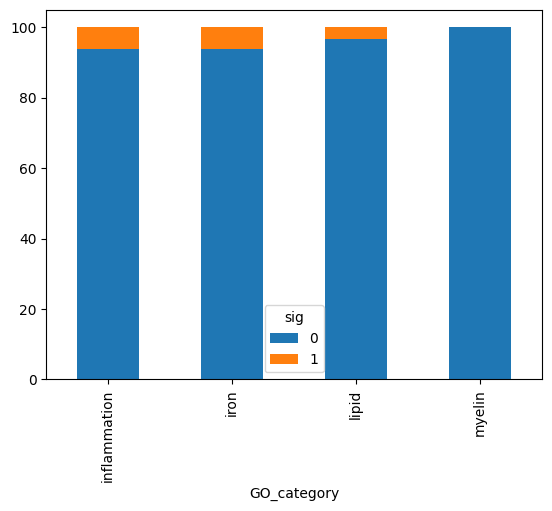

In [269]:
#pvals_melt[['sig', 'GO_category']].plot.bar(x='GO_category', stacked=True, figsize=(8,6))
pvals_melt[pvals_melt['variable']=='QSM'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True)


<AxesSubplot:xlabel='GO_category'>

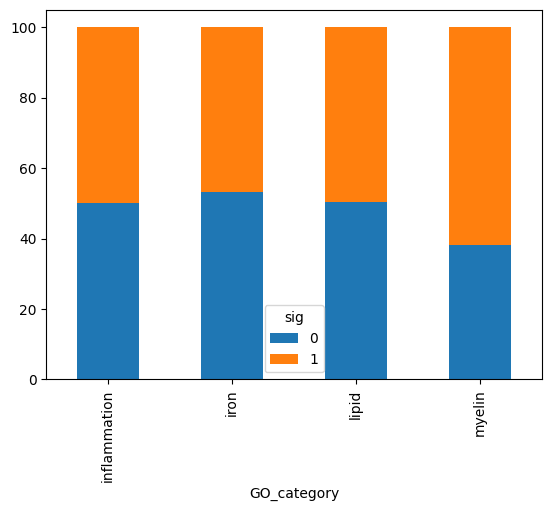

In [270]:
pvals_melt[pvals_melt['variable']=='R1'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True)

<AxesSubplot:xlabel='GO_category'>

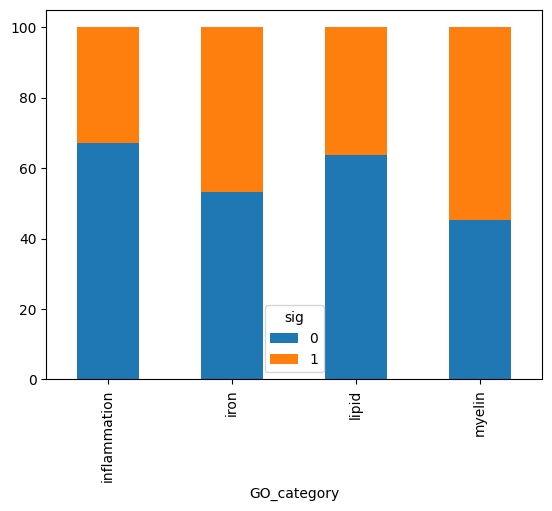

In [271]:
pvals_melt[pvals_melt['variable']=='R2s'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True)

<AxesSubplot:xlabel='GO_category'>

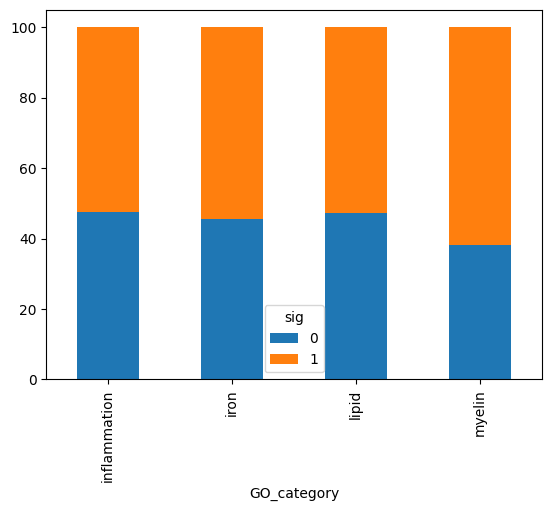

In [272]:
pvals_melt[pvals_melt['variable']=='MTsat'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True)


## Overall big picture

- heatmap summarising correlation Rs
- Which keywords have most significant pathways (%)? 
- Which qMRI metric has most significant correlations with each keyword? 


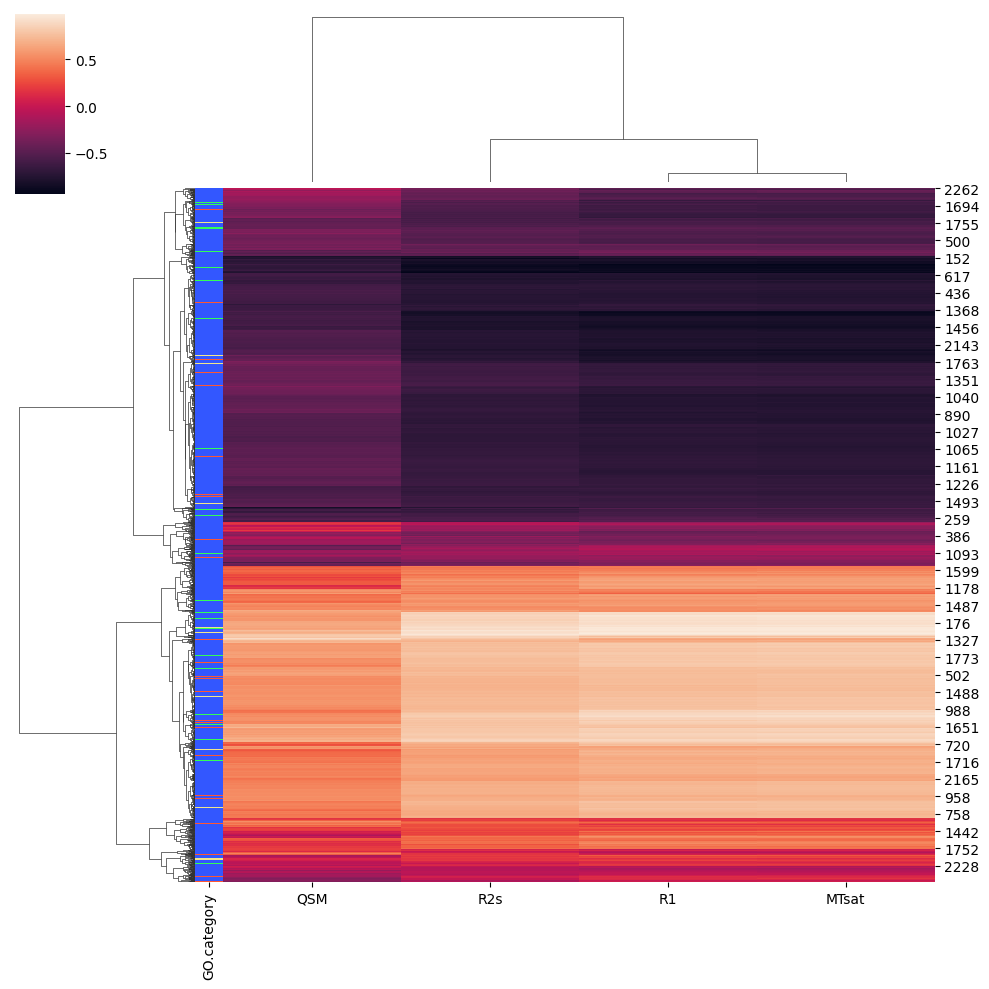

In [273]:
rho_pathways = pd.read_csv('../../plots/02a-4layers_qMRIvsST_noendo/Stats_expanded_pathway_analysis_rho.csv')
lut = dict(zip(rho_pathways['GO.category'].unique(), ["#FF5733", "#33FF57", "#3357FF", "#F0E68C"]))
row_colors = rho_pathways['GO.category'].map(lut)
sns.clustermap(rho_pathways[['QSM','R1','R2s','MTsat']], row_colors = row_colors)

In [274]:
(pvals_melt['value']<0.01).value_counts()

False    4723
True     4545
Name: value, dtype: int64

In [275]:
(pvals_melt['padj']<0.01).value_counts()

False    5960
True     3308
Name: padj, dtype: int64

In [276]:

#pvals_melt = pd.melt(terms, id_vars=['GO_term'], value_vars=['QSM', 'R1', 'R2s', 'MTsat'])
#pvals_melt

#fdr(pvals_melt['value'], alpha=0.05, method='indep', is_sorted=False)


## Inflammation analysis

In [277]:
terms = pd.read_csv('../../raw_data/keyword_search_amiGO/inflammation_GO_terms.csv')
terms['GO_term'] = terms['GO_term'].str.replace(':', '')
terms['GO_term'] = 'inflammation_'+terms['GO_term']

#terms = terms.merge(pvals, left_on = 'GO_term', right_on = 'Unnamed: 0', how = 'inner')

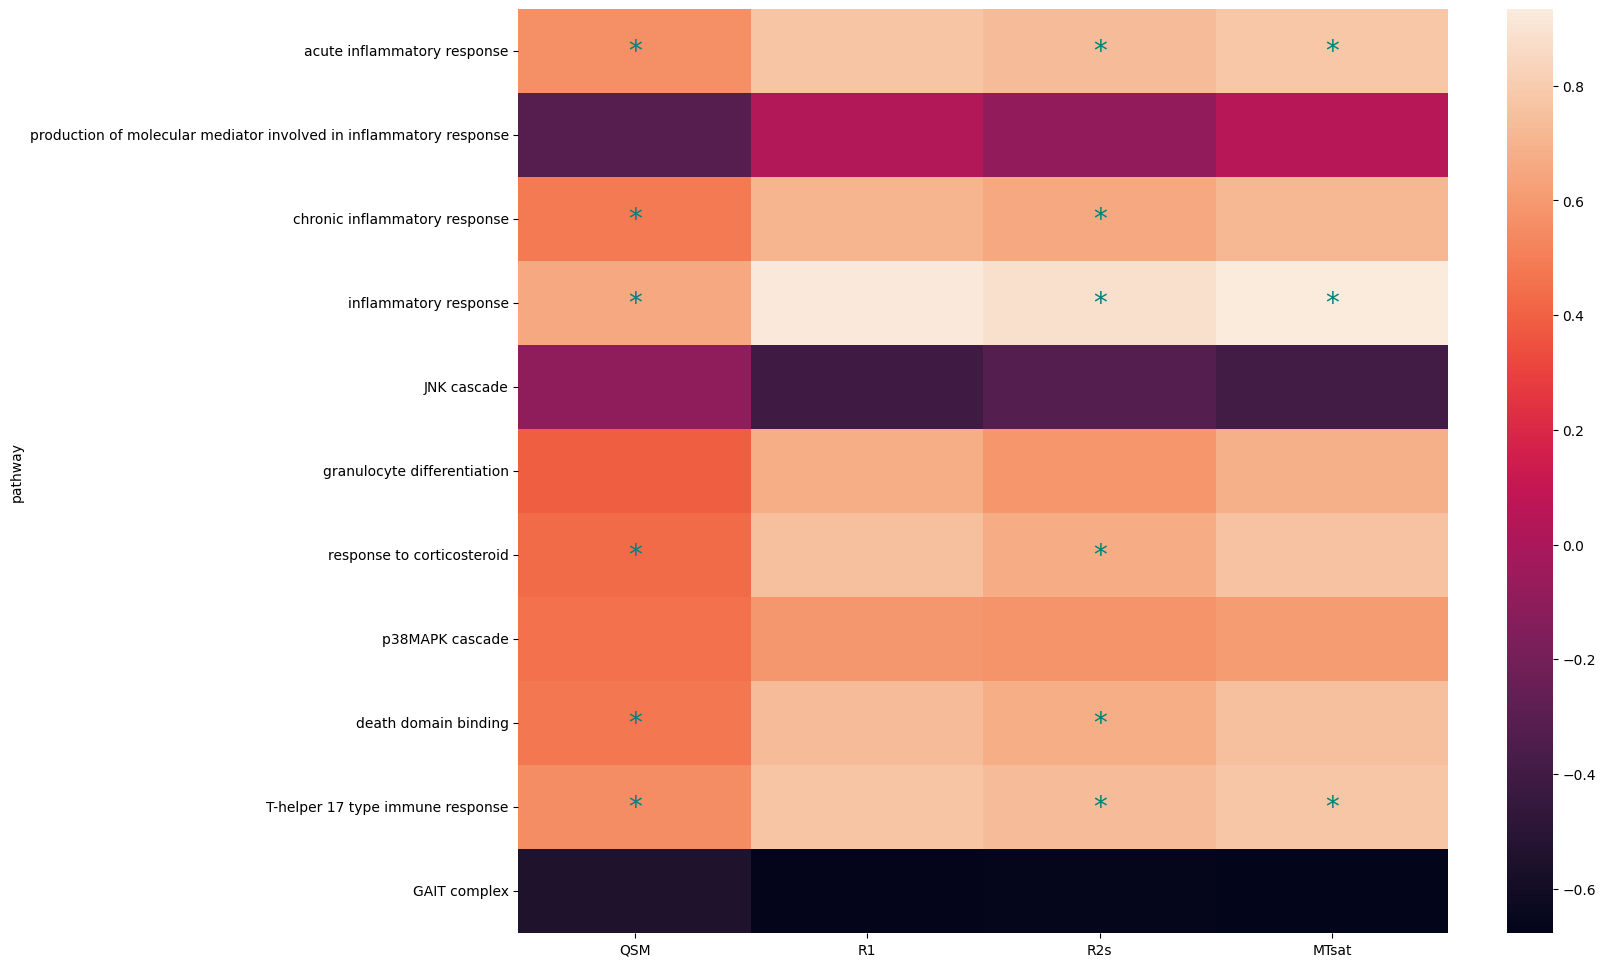

In [278]:
inflammation = rho_pathways[rho_pathways['GO.category']=='inflammation']
inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
inflammation.set_index('pathway', inplace = True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(inflammation[['QSM','R1','R2s','MTsat']])
inflam_pvals = pvals_pivot[pvals_pivot.index.isin(inflammation['Unnamed: 0'])]
for i in range(inflammation[['QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(inflammation[['QSM','R1','R2s','MTsat']].shape[1]):
        if inflam_pvals.iloc[i,j]<0.01:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=20, color='teal')

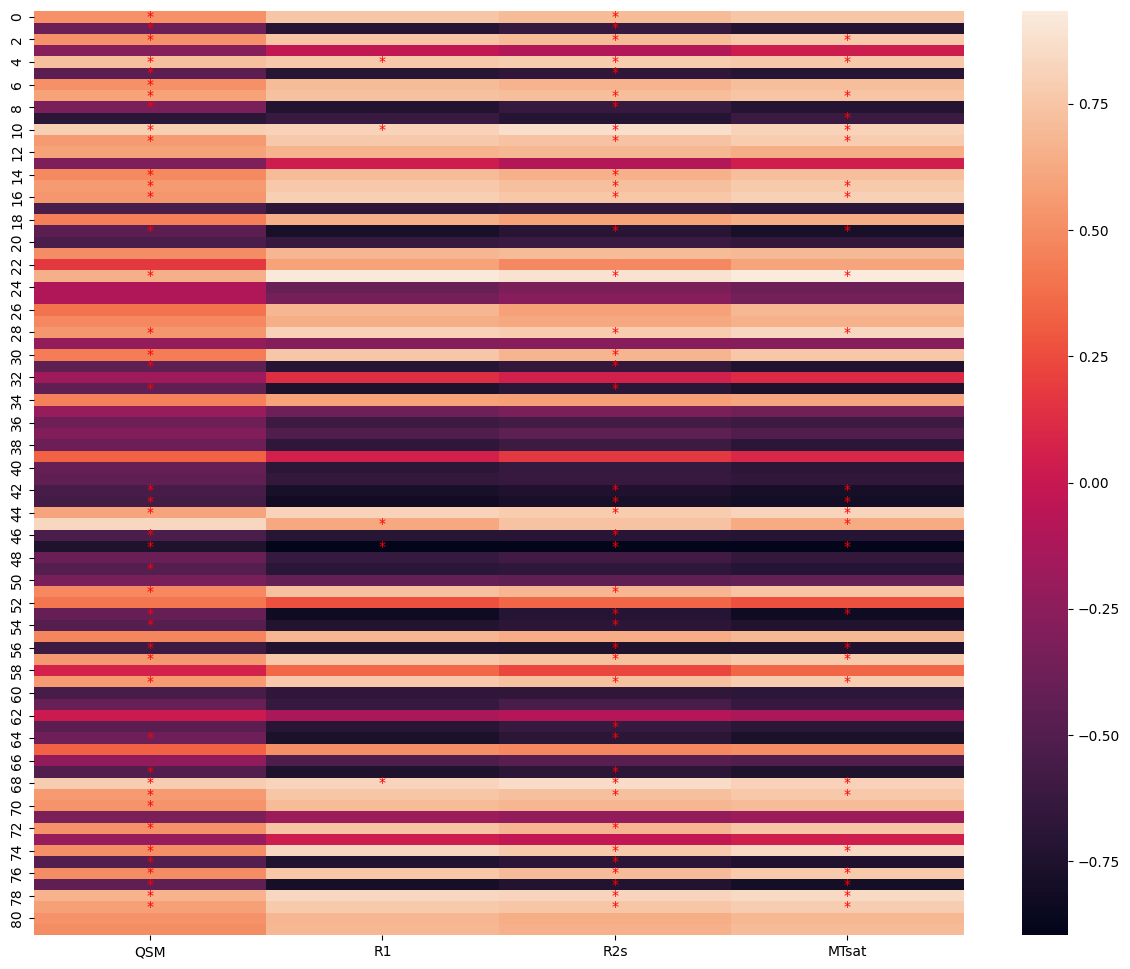

In [279]:

#terms

#terms = terms.merge(pvals, left_on = 'GO_term', right_on = 'Unnamed: 0', how = 'inner')
inflammation = rho_pathways[rho_pathways['GO.category']=='inflammation']
#inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
#inflammation.set_index('pathway', inplace = True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(inflammation[['QSM','R1','R2s','MTsat']])
inflam_pvals = pvals_pivot[pvals_pivot.index.isin(inflammation['Unnamed: 0'])]
for i in range(inflammation[['QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(inflammation[['QSM','R1','R2s','MTsat']].shape[1]):
        if inflam_pvals.iloc[i,j]<0.01:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=10, color='red')

## Myelin analysis

In [293]:
inflammation = rho_pathways[rho_pathways['GO.category']=='myelin']
#inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')

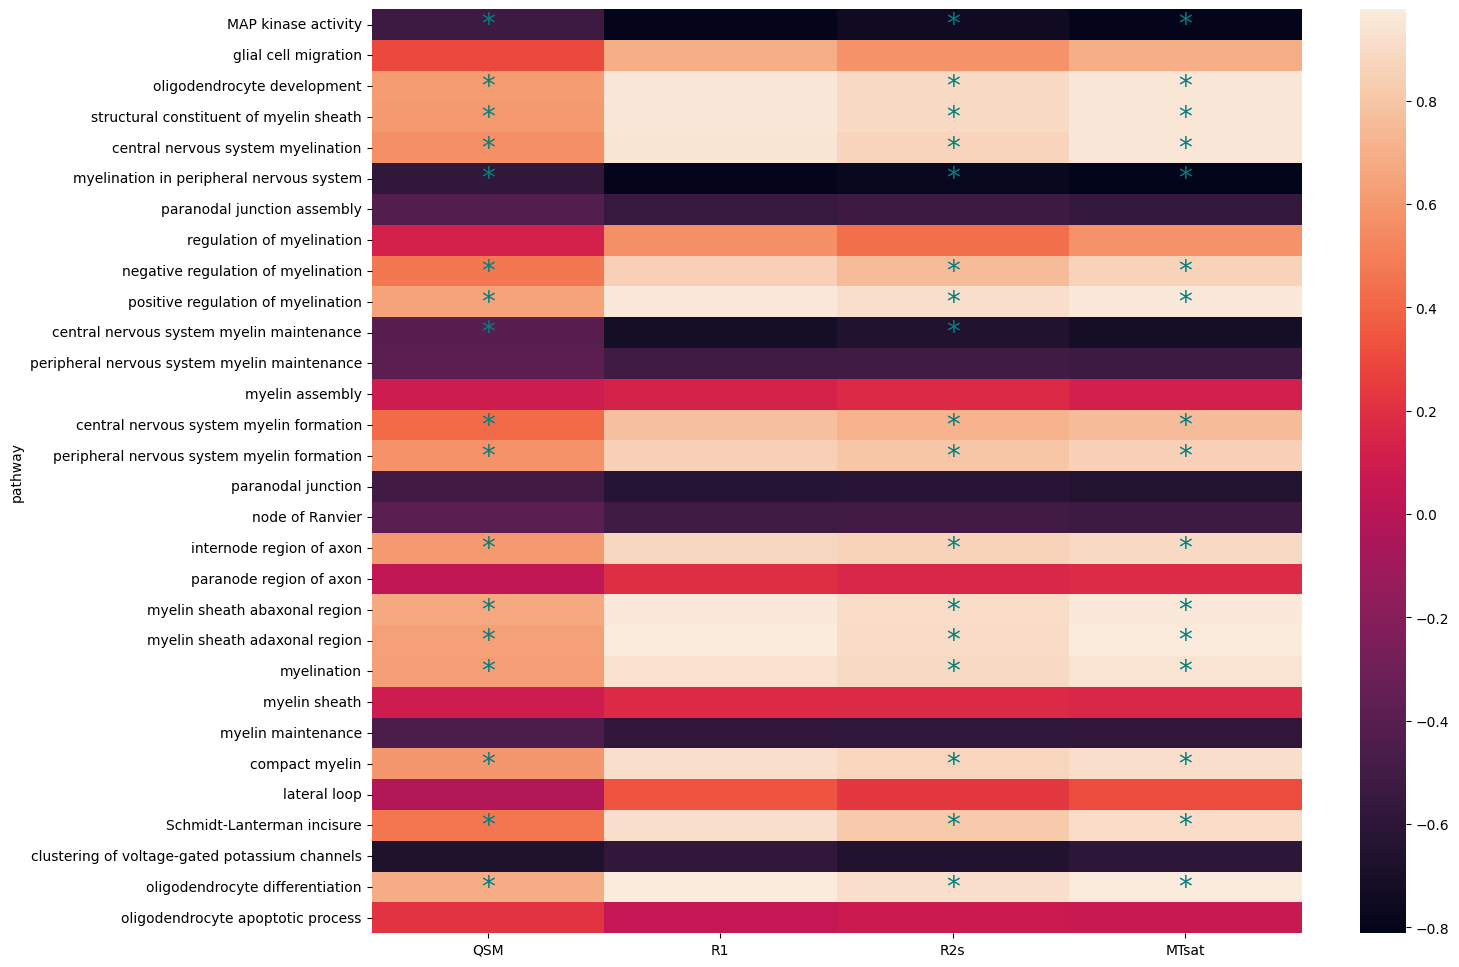

In [295]:

#terms
terms = pd.read_csv('../../raw_data/keyword_search_amiGO/myelin_GO_terms.csv')
terms['GO_term'] = terms['GO_term'].str.replace(':', '')
terms['GO_term'] = 'myelin_'+terms['GO_term']

inflammation = rho_pathways[rho_pathways['GO.category']=='myelin']
inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
inflammation.set_index('pathway', inplace = True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(inflammation[['QSM','R1','R2s','MTsat']])
inflam_pvals = pvals_pivot[pvals_pivot.index.isin(inflammation['Unnamed: 0'])]
for i in range(inflammation[['QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(inflammation[['QSM','R1','R2s','MTsat']].shape[1]):
        if inflam_pvals.iloc[i,j]<0.01:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=20, color='teal')

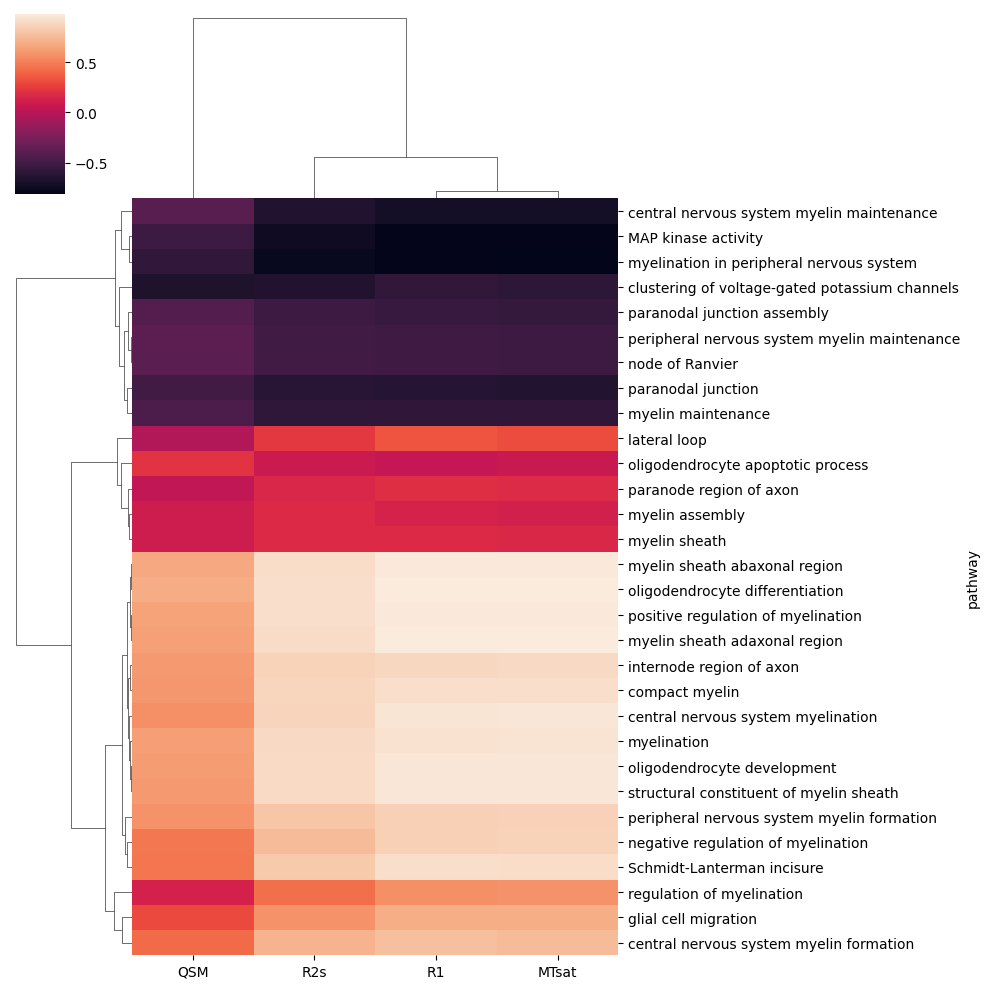

In [281]:
terms = pd.read_csv('../../raw_data/keyword_search_amiGO/myelin_GO_terms.csv')
terms['GO_term'] = terms['GO_term'].str.replace(':', '')
terms['GO_term'] = 'myelin_'+terms['GO_term']
#terms

inflammation = rho_pathways[rho_pathways['GO.category']=='myelin']
inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
inflammation.set_index('pathway', inplace = True)
sns.clustermap(inflammation[['QSM','R1','R2s','MTsat']])

## Iron analysis

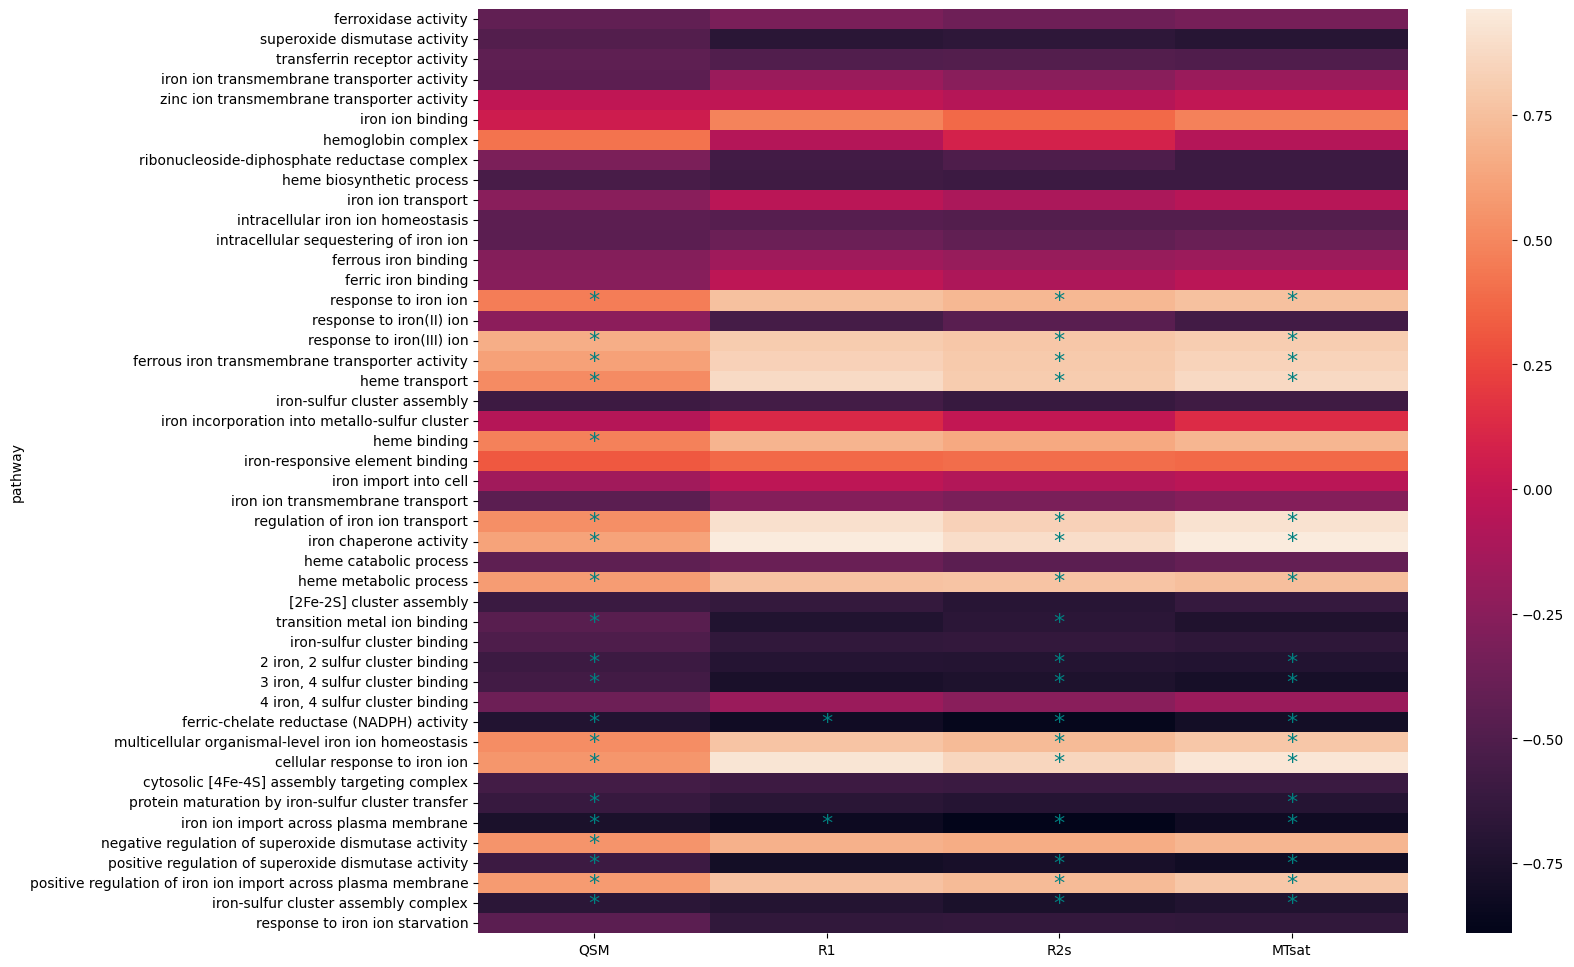

In [298]:

#terms
terms = pd.read_csv('../../raw_data/keyword_search_amiGO/iron_GO_terms.csv')
terms['GO_term'] = terms['GO_term'].str.replace(':', '')
terms['GO_term'] = 'iron_'+terms['GO_term']

inflammation = rho_pathways[rho_pathways['GO.category']=='iron']
inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
inflammation.set_index('pathway', inplace = True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(inflammation[['QSM','R1','R2s','MTsat']])
inflam_pvals = pvals_pivot[pvals_pivot.index.isin(inflammation['Unnamed: 0'])]
for i in range(inflammation[['QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(inflammation[['QSM','R1','R2s','MTsat']].shape[1]):
        if inflam_pvals.iloc[i,j]<0.01:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=16, color='teal')

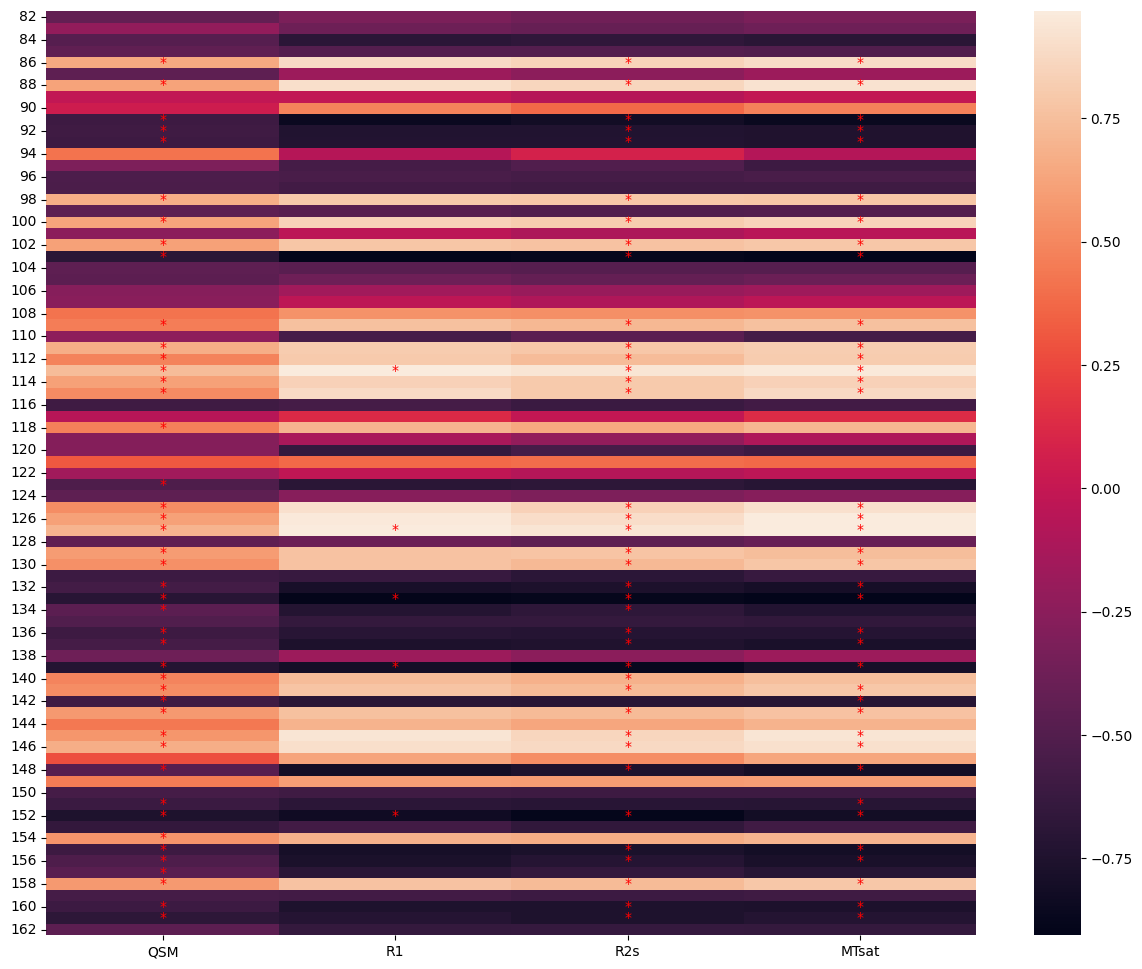

In [282]:

#terms

inflammation = rho_pathways[rho_pathways['GO.category']=='iron']
#inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
#inflammation.set_index('pathway', inplace = True)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(inflammation[['QSM','R1','R2s','MTsat']])
inflam_pvals = pvals_pivot[pvals_pivot.index.isin(inflammation['Unnamed: 0'])]
for i in range(inflammation[['QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(inflammation[['QSM','R1','R2s','MTsat']].shape[1]):
        if inflam_pvals.iloc[i,j]<0.01:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=10, color='red')

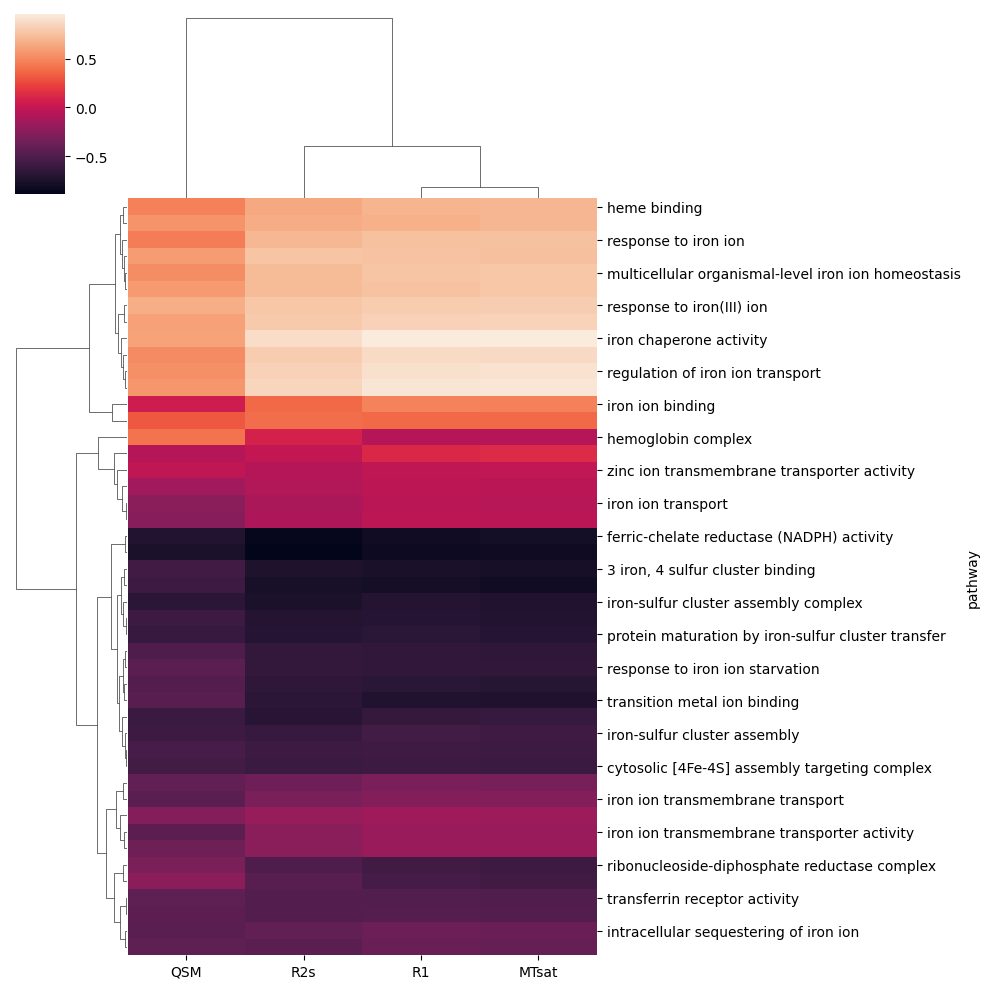

In [283]:
terms = pd.read_csv('../../raw_data/keyword_search_amiGO/iron_GO_terms.csv')
terms['GO_term'] = terms['GO_term'].str.replace(':', '')
terms['GO_term'] = 'iron_'+terms['GO_term']
#terms

inflammation = rho_pathways[rho_pathways['GO.category']=='iron']
inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')
inflammation.set_index('pathway', inplace = True)
sns.clustermap(inflammation[['QSM','R1','R2s','MTsat']])

## Cell counts

In [284]:
counts = pd.read_csv('../../plots/02a-4layers_qMRIvsST_noendo/Stats_control_qMRI_vs_cell_count.csv')
counts

,qMRI,cell_type,T,rho,R2,p,corr_p
0,QSM,Astro,-2.173440,-0.516260,0.266525,4.881836e-02,7.100853e-02
1,R1,Astro,-0.900374,-0.242279,0.058699,3.842976e-01,3.842976e-01
2,R2s,Astro,-1.086344,-0.288487,0.083225,2.970604e-01,3.656128e-01
3,MTsat,Astro,-0.983170,-0.263077,0.069210,3.434684e-01,3.663663e-01
4,QSM,Micro,1.017327,0.271553,0.073741,3.275585e-01,3.663663e-01
5,R1,Micro,3.287822,0.673799,0.454006,5.883986e-03,1.546991e-02
6,R2s,Micro,2.492274,0.568612,0.323320,2.697889e-02,4.316623e-02
7,MTsat,Micro,3.204829,0.664352,0.441363,6.903118e-03,1.546991e-02
8,QSM,Oligo,3.048733,0.645681,0.416904,9.322676e-03,1.657365e-02
9,R1,Oligo,12.227856,0.959172,0.920010,1.667138e-08,2.667420e-07


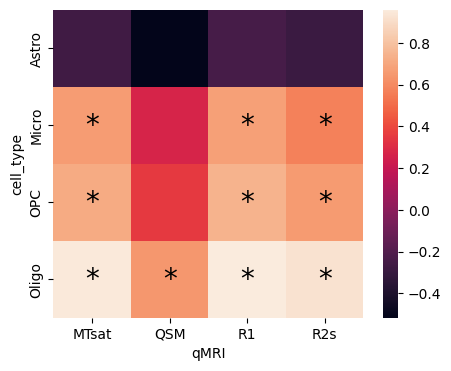

In [285]:
import matplotlib.pyplot as plt
piv_counts = pd.pivot_table(counts, values='rho', index=['cell_type'],
                       columns=['qMRI'], aggfunc="sum")
pvals = pd.pivot_table(counts, values='corr_p', index=['cell_type'],
                       columns=['qMRI'], aggfunc="sum")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(piv_counts,ax=ax)
for i in range(piv_counts.shape[0]):
    for j in range(piv_counts.shape[1]):
        if pvals.iloc[i,j]<0.05:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=20, color='black')